<a href="https://colab.research.google.com/github/federico2018lc/Estudio_Dataset_MedicalCostPersonal-Datasets_Kaggle/blob/main/modulo2AnalistaDatos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**PROYECTO**: Análisis de Costos Medicos

Materia: Ciencia de Datos 2

Prof: Sol Figueroa

Integrantes:

Mariela Yacci		marielayacci@gmail.com

Emanuel Toledo 		j.emanuel.toledo@gmail.com

Federico López Coria		federico2018lc@gmail.com

Marcela Luciana Knecht		lumik1984cva@gmail.com

Matias Rovaretti 		rovarettimatias123@gmail.com

## 1. Comprensión del negocio

La comprensión del negocio permite definir con claridad el problema que se busca resolver antes de avanzar con el análisis de datos. En esta etapa se identifican los objetivos, las personas involucradas, las restricciones y el resultado esperado del proyecto.

### 1.a Determinar objetivos del negocio

- ¿Cuál es el problema que una persona, un área o una organización necesita resolver?
- ¿Qué decisión podría tomarse de manera diferente si el proyecto funciona?
- ¿Quiénes son los principales interesados (*stakeholders*) y qué esperan del proyecto?

### 1.b Situación actual

- Datos disponibles.
- Personas y roles involucrados.
- Tiempo y herramientas disponibles.
- Restricciones legales, de privacidad o de presupuesto.
- Riesgos identificables desde el inicio.

### 1.c Objetivos analíticos

El objetivo analítico traduce una necesidad del negocio en una tarea concreta de análisis de datos o modelado.

La idea central es pasar de una intención general a un problema analítico con una tarea definida, variables relevantes y un uso concreto del resultado.

### 1.d Plan inicial del proyecto

En esta etapa se realiza una primera estimación de las fases de trabajo, los tiempos necesarios y las herramientas que se utilizarán. La planificación detallada se desarrollará posteriormente dentro del proceso analítico.


##  2.Comprensión de los datos

La comprensión de los datos se organiza como una secuencia de tareas. El objetivo no es solamente observar el dataset, sino entender su origen, su estructura, sus variables y su calidad antes de realizar transformaciones o construir modelos.

### 2.1 Recolección de datos iniciales
- El origen de los datos.
- El contexto en el que fueron obtenidos.
- Las posibles limitaciones del dataset.

Para el proyecto se utiliza el dataset **Medical Cost Personal Datasets**, disponible en Kaggle.

**Fuente:** [Medical Cost Personal Datasets — Kaggle](https://www.kaggle.com/code/mragpavank/medical-cost-personal-datasets)

El conjunto de datos contiene información individual relacionada con características personales y costos médicos.


Carga del dataset y librerías

A continuación se importan las librerías necesarias y se carga el dataset que se utilizará durante el análisis.

Esta celda establece el entorno de trabajo y permite verificar inicialmente las dimensiones del conjunto de datos.


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno
import plotly.express as px
import warnings
import plotly.express as px
warnings.filterwarnings("ignore")
#
url='https://raw.githubusercontent.com/federico2018lc/Estudio_Dataset_MedicalCostPersonal-Datasets_Kaggle/refs/heads/main/insurance.csv'
df= pd.read_csv(url,sep=',')
df.shape


(1338, 7)

### 2.B Descripción de los datos

- La cantidad total de filas y columnas.
- Los nombres de las variables.
- Los tipos de datos presentes en cada columna.

Esta revisión permite comprender la estructura básica del conjunto de datos antes de continuar con análisis más específicos.


####  Diccionario de datos
El dataset contiene las siguientes variables:
Edad: números enteros  - variable cuantitativa discreta

Sex: variable categorica  

bmi:  numeros con decimales - variable cuantitativa continua

Children (hijos): variable cuantitativa discreta

Smoker (fumador): variable categorica nominal

Region: variable categorica nominal

charges: (costos medicos): varialbe cuantitativa continua





| Variable | Descripción | Tipo de variable |
|---|---|---|
| `age` | Edad de la persona, expresada en años. | Cuantitativa discreta |
| `sex` | Sexo registrado de la persona. | Categórica nominal |
| `bmi` | Índice de masa corporal (*Body Mass Index*). | Cuantitativa continua |
| `children` | Cantidad de hijos o personas dependientes consideradas en el registro. | Cuantitativa discreta |
| `smoker` | Indica si la persona es fumadora. | Categórica nominal |
| `region` | Región geográfica de residencia. | Categórica nominal |
| `charges` | Costos médicos individuales registrados. | Cuantitativa continua |

Este diccionario facilita la interpretación de las variables utilizadas en las etapas posteriores del análisis.



In [ ]:
#primeras filas
df.head(10)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [ ]:
#cuantas filas y columnas hay
print('Total filas: ',df.shape[0])
print('Total colmumnas: ',df.shape[1])



Total filas:  1338
Total colmumnas:  7


In [ ]:
#como se llaman las columnas ( por si luego necestamos copiarlas y/o cambiar)
list(df.columns)


['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

In [ ]:
#ahora, info general para luego ver los tipos de variables que tenemos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


### 2.C Exploración de los datos

La exploración permite conocer el comportamiento de las variables y detectar relaciones relevantes. Puede incluir:

- Estadística descriptiva básica.
- Distribuciones de variables.
- Relaciones entre variables.
- Visualizaciones mediante histogramas, boxplots y gráficos de dispersión.

Estadística sobre Variables Numéricas

In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Las variables numéricas presentan escalas y comportamientos diferentes. `age` se concentra alrededor de los 39 años, `bmi` alrededor de 30,7 y `children` tiene una mediana de 1. En `charges` la media es mayor que la mediana, lo que anticipa una distribución asimétrica hacia valores altos y justifica revisar posibles valores atípicos.


#### **Variable a Predecir: `Charges`**


Costos médicos individuales registrados.

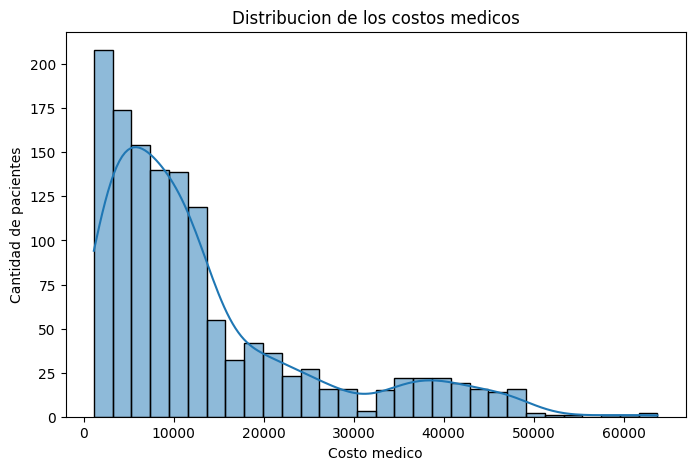

In [ ]:
#visualizamos como estan distribuidos los costos medicos
plt.figure(figsize=(8,5))

sns.histplot(df["charges"],kde=True)
plt.title("Distribucion de los costos medicos")
plt.xlabel("Costo medico")
plt.ylabel("Cantidad de pacientes")

plt.show()

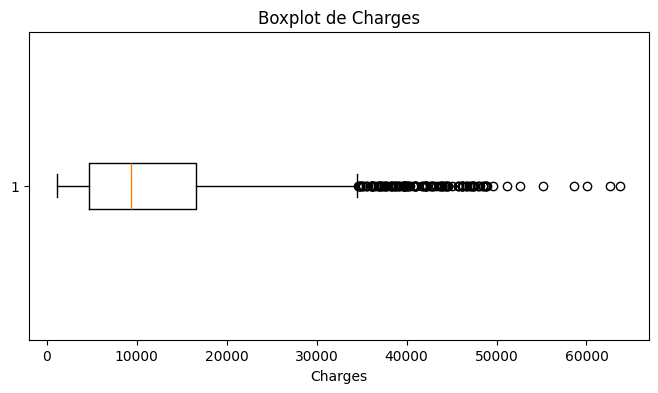

In [ ]:
plt.figure(figsize=(8, 4))

plt.boxplot(df["charges"], vert=False)

plt.title("Boxplot de Charges")
plt.xlabel("Charges")

plt.show()

In [ ]:
fig = px.histogram(
    df,
    x="charges",
    nbins=30,
    title="Distribución de Charges"
)

fig.update_layout(
    xaxis_title="Charges",
    yaxis_title="Frecuencia",
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=True)
)

fig.show()

In [ ]:
# Cuantificamos posibles valores atípicos de la variable objetivo mediante el criterio del IQR
q1 = df["charges"].quantile(0.25)
q3 = df["charges"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_charges = df[
    (df["charges"] < limite_inferior) |
    (df["charges"] > limite_superior)
]

print(f"Q1: {q1:.2f}")
print(f"Mediana: {df['charges'].median():.2f}")
print(f"Q3: {q3:.2f}")
print(f"Límite superior para outliers: {limite_superior:.2f}")
print(f"Cantidad de posibles outliers: {len(outliers_charges)}")
print(f"Porcentaje de posibles outliers: {len(outliers_charges) / len(df) * 100:.2f}%")


Q1: 4740.29
Mediana: 9382.03
Q3: 16639.91
Límite superior para outliers: 34489.35
Cantidad de posibles outliers: 139
Porcentaje de posibles outliers: 10.39%


`charges` presenta una marcada asimetría positiva: la mayoría de los registros se concentra en costos bajos y medios, mientras que existe un grupo de costos considerablemente más altos. El boxplot permite identificar esos valores como posibles *outliers*. Por el momento no se eliminan, ya que pueden representar pacientes reales de alto costo y ser relevantes para el problema de negocio.


#### Distribución de `age`, `bmi` y `children`


In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=("Distribución de la edad", "Distribución del BMI", "Distribución de hijos")
)

fig.add_trace(
    go.Histogram(x=df["age"], nbinsx=20, name="Edad"),
    row=1, col=1
)

fig.add_trace(
    go.Histogram(x=df["bmi"], nbinsx=30, name="BMI"),
    row=1, col=2
)

fig.add_trace(
    go.Histogram(x=df["children"], name="Hijos"),
    row=1, col=3
)

fig.update_xaxes(title_text="Edad", showgrid=True, row=1, col=1)
fig.update_xaxes(title_text="BMI", showgrid=True, row=1, col=2)
fig.update_xaxes(title_text="Cantidad de hijos", showgrid=True, dtick=1, row=1, col=3)

fig.update_yaxes(title_text="Frecuencia", showgrid=True, row=1, col=1)
fig.update_yaxes(showgrid=True, row=1, col=2)
fig.update_yaxes(showgrid=True, row=1, col=3)

fig.update_layout(
    width=1100,
    height=420,
    showlegend=False,
    title_text="Distribución de variables numéricas"
)

fig.show()


**Interpretación:**  
La edad presenta una distribución amplia a lo largo del rango observado. El `bmi` se concentra principalmente alrededor de valores cercanos a 30, mientras que `children` se concentra en cantidades bajas, especialmente entre 0 y 2 hijos. Estas distribuciones permiten reconocer que las tres variables tienen comportamientos diferentes y que conviene analizarlas por separado frente a `charges`.


###### Boxplots de `age`, `bmi` y `children`


In [ ]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=1, cols=3,
    subplot_titles=("Boxplot de la edad", "Boxplot del BMI", "Boxplot de hijos")
)

fig.add_trace(
    go.Box(y=df["age"], name="Edad"),
    row=1, col=1
)

fig.add_trace(
    go.Box(y=df["bmi"], name="BMI"),
    row=1, col=2
)

fig.add_trace(
    go.Box(y=df["children"], name="Hijos"),
    row=1, col=3
)

fig.update_yaxes(title_text="Edad", showgrid=True, row=1, col=1)
fig.update_yaxes(title_text="BMI", showgrid=True, row=1, col=2)
fig.update_yaxes(title_text="Cantidad de hijos", showgrid=True, row=1, col=3)

fig.update_xaxes(showgrid=True, row=1, col=1)
fig.update_xaxes(showgrid=True, row=1, col=2)
fig.update_xaxes(showgrid=True, row=1, col=3)

fig.update_layout(
    width=950,
    height=520,
    showlegend=False,
    title_text="Boxplots de variables numéricas"
)

fig.show()


**Interpretación:**  
Los boxplots muestran que `age` y `children` no presentan valores extremos especialmente problemáticos. En `bmi` aparecen algunos valores altos que podrían considerarse atípicos estadísticamente, aunque en esta etapa no se eliminan porque pueden corresponder a observaciones reales y aportar información útil al análisis.


#### Relaciones entre variables.


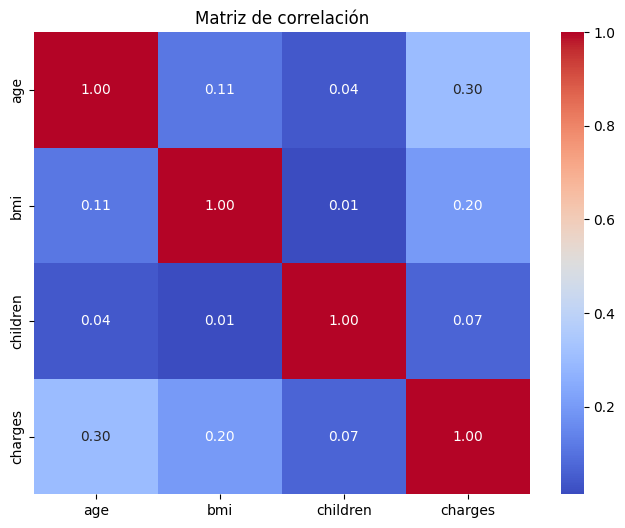

In [ ]:
#realizamos un mapa de calor para ver la correlacion que tienen nuestras variables numericas con la varible "charges"

corr = df.corr(numeric_only=True)

plt.figure(figsize=(8,6))

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Matriz de correlación")

plt.show()

**Interpretación:**  
Entre las variables numéricas, `age` es la que muestra la relación lineal positiva más clara con `charges`. `bmi` también presenta una asociación positiva, aunque más débil, mientras que `children` muestra una relación lineal baja con el costo médico. Esto indica que las variables numéricas por sí solas no explican completamente las diferencias en `charges`, por lo que conviene incorporar las variables categóricas al análisis.


##### Relación entre `smoker` y `charges`


In [ ]:
fig = px.box(
    df,
    x="smoker",
    y="charges",
    points="outliers",
    title="Costos médicos según condición de fumador"
)

fig.update_layout(
    width=700,
    height=500,
    xaxis_title="Fumador",
    yaxis_title="Charges",
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=True)
)

fig.show()


**Interpretación:**  
La condición de fumador muestra una separación clara en los costos médicos: las personas fumadoras tienden a presentar valores de `charges` considerablemente más altos. Esta variable aparece como una candidata importante para explicar o predecir los costos.


##### Relación entre `bmi`, `charges` y condición de fumador


In [ ]:
fig = px.scatter(
    df,
    x="bmi",
    y="charges",
    color="smoker",
    title="BMI y costos médicos según condición de fumador",
    opacity=0.7
)

fig.update_layout(
    width=800,
    height=500,
    xaxis_title="BMI",
    yaxis_title="Charges",
    xaxis=dict(showgrid=True),
    yaxis=dict(showgrid=True)
)

fig.show()


**Interpretación:**  
La relación entre `bmi` y `charges` no es igual para todos los individuos. Al diferenciar por condición de fumador se aprecia que los costos elevados se concentran especialmente entre fumadores, y el BMI parece adquirir mayor importancia dentro de ese grupo.


### Conclusión de la exploración de datos

La exploración muestra que los costos médicos no se distribuyen de manera uniforme y presentan una cola hacia valores altos. Entre las variables analizadas, la condición de fumador aparece como el factor con mayor diferenciación de costos, seguida por la edad y, en menor medida, el BMI. Los valores extremos de `charges` se conservarán inicialmente porque pueden representar casos reales de alto costo y contienen información relevante para el objetivo del proyecto.


### 2.D Verificación de la calidad de los datos

En esta fase se revisa la calidad del dataset antes de avanzar hacia la preparación de los datos. El objetivo es **identificar y documentar** posibles problemas, sin corregirlos todavía.


#### 2.D.1 Valores faltantes

- Verificar si existen valores nulos o ausentes.
- Identificar en qué variables aparecen.
- Calcular cuántos representan respecto del total de registros.

**Interpretación:**  
_Completar a partir de los resultados obtenidos._


#### 2.D.2 Registros duplicados

- Verificar si existen filas repetidas.
- Cuantificar la cantidad de registros duplicados.

**Interpretación:**  
_Completar a partir de los resultados obtenidos._


#### 2.D.3 Valores atípicos (*outliers*)

- Revisar especialmente las variables numéricas.
- Identificar posibles valores extremos mediante estadística descriptiva y boxplots.
- Evaluar si parecen errores o casos reales.

**Interpretación:**  
_Completar a partir de los resultados obtenidos._


#### 2.D.4 Categorías inconsistentes

- Revisar los valores posibles de las variables categóricas: `sex`, `smoker` y `region`.
- Detectar diferencias de escritura, categorías inesperadas o valores inconsistentes.

**Interpretación:**  
_Completar a partir de los resultados obtenidos._


#### 2.D.5 Tipos de datos

- Verificar que cada columna tenga un tipo de dato coherente con su significado.
- Confirmar que las variables numéricas sean numéricas y las categóricas estén correctamente representadas.

**Interpretación:**  
_Completar a partir de los resultados obtenidos._


#### Conclusión de la calidad de los datos

_Resumir brevemente los principales problemas encontrados y señalar cuáles deberán tratarse posteriormente durante la preparación de los datos._

> **Importante:** en esta etapa los problemas se identifican y documentan. Su corrección corresponde a la fase de preparación de los datos.
